In [3]:
import pandas as pd
import numpy as np

In [4]:
trust = pd.read_csv("../epinions/epinions/user_rating.txt",sep=r"\s+",header=None,names=["source","target","value","creation"])

In [5]:
mc = pd.read_csv("../epinions/epinions/mc.txt",sep="|",header=None,names=["content_id","author_id","subject_id"])

In [6]:
ratings = pd.read_csv("../epinions/epinions/rating.txt",sep=r"\s+",header=None,names=[ "object_id","member_id","rating","status","creation","last_modified","type","vertical_id"])

In [7]:
interaction = ratings.merge(
    mc,
    left_on="object_id",
    right_on="content_id",
    how="inner"
)

In [8]:
interaction

,object_id,member_id,rating,status,creation,last_modified,type,vertical_id,content_id,author_id,subject_id
0,139431556,591156,5,0,2001/01/10,1,2518365,NaN,139431556,2252443524,3.357800e+04
1,139431556,1312460676,5,0,2001/01/10,1,2518365,NaN,139431556,2252443524,3.357800e+04
2,139431556,204358,5,0,2001/01/10,1,2518365,NaN,139431556,2252443524,3.357800e+04
3,139431556,368725,5,0,2001/01/10,1,2518365,NaN,139431556,2252443524,3.357800e+04
4,139431556,277629,5,0,2001/01/10,1,2518365,NaN,139431556,2252443524,3.357800e+04
...,...,...,...,...,...,...,...,...,...,...,...
13668099,891503,311238,5,0,2001/01/10,2001/12/27,1,2522499.0,891503,342187,3.423066e+11
13668100,891503,210412,5,0,2001/01/10,2001/12/27,1,2522499.0,891503,342187,3.423066e+11
13668101,891503,351471,5,0,2001/01/10,2001/12/27,1,2522499.0,891503,342187,3.423066e+11
13668102,891503,394639,5,0,2001/01/10,2001/12/27,1,2522499.0,891503,342187,3.423066e+11


In [17]:
interaction = interaction.rename(columns={
    "member_id": "source",
    "author_id": "target"
})

In [18]:
interaction = interaction[
    interaction["source"] != interaction["target"]
] #remove self ratings

In [19]:
interaction["relationship"] = "ReviewRating"

In [20]:
interaction = interaction[
    [
        "source",
        "target",
        "rating",
        "relationship"
    ]
]

In [17]:
interaction.to_csv("interaction_features.csv", index=False)

In [13]:
author_features = interaction.groupby("target").agg(
    reviews_received=("rating","count"),
    avg_rating=("rating","mean")
)

In [14]:
author_features

,reviews_received,avg_rating
target,,
199775,4,3.000000
199776,16,4.187500
199779,11,4.545455
199780,2,4.000000
199781,1103,4.836809
...,...,...
46357254020,2,4.000000
46365249412,2,4.000000
46366429060,1,3.000000


In [15]:
member_features = interaction.groupby("source").agg(
    ratings_given=("rating","count"),
    avg_given=("rating","mean")
)

In [16]:
member_features

,ratings_given,avg_given
source,,
199775,1,5.000000
199781,498,4.373494
199783,3,5.000000
199784,17,4.705882
199786,32,4.656250
...,...,...
46364331908,1,4.000000
46368788356,1,5.000000
46369574788,2,5.000000


In [19]:
interaction["edge_type"] = "ReviewRating"
interaction["weight"] = interaction["rating"]
interaction

,source,target,rating,relationship,edge_type,weight
0,591156,2252443524,5,ReviewRating,ReviewRating,5
1,1312460676,2252443524,5,ReviewRating,ReviewRating,5
2,204358,2252443524,5,ReviewRating,ReviewRating,5
3,368725,2252443524,5,ReviewRating,ReviewRating,5
4,277629,2252443524,5,ReviewRating,ReviewRating,5
...,...,...,...,...,...,...
13668099,311238,342187,5,ReviewRating,ReviewRating,5
13668100,210412,342187,5,ReviewRating,ReviewRating,5
13668101,351471,342187,5,ReviewRating,ReviewRating,5
13668102,394639,342187,5,ReviewRating,ReviewRating,5


In [20]:
sample_nodes = pd.read_csv("sample_nodes.csv")
selected_users = set(sample_nodes["Id"])

interaction_sample = interaction[
    interaction["source"].isin(selected_users) &
    interaction["target"].isin(selected_users)
]


In [21]:
trust = pd.read_csv("sample_edges.csv")
trust

,Source,Target,Type,Weight,Relationship
0,386501,291602,Directed,1,Trust
1,3169947524,3222572932,Directed,1,Trust
2,356173,412995,Directed,1,Trust
3,556414,240454,Directed,1,Trust
4,692821,294288,Directed,1,Trust
...,...,...,...,...,...
99995,339957,210284,Directed,1,Trust
99996,3187838852,3214512004,Directed,1,Trust
99997,286861,307866,Directed,1,Trust
99998,3215953796,3220279172,Directed,1,Trust


In [23]:
interaction_sample

,source,target,rating,relationship,edge_type,weight
24,225918,641452,5,ReviewRating,ReviewRating,5
25,287513,641452,5,ReviewRating,ReviewRating,5
26,200338,641452,5,ReviewRating,ReviewRating,5
27,289843,641452,5,ReviewRating,ReviewRating,5
28,315530,641452,5,ReviewRating,ReviewRating,5
...,...,...,...,...,...,...
13668058,361989,3134492548,2,ReviewRating,ReviewRating,2
13668059,232924,3134492548,2,ReviewRating,ReviewRating,2
13668060,454791,3134492548,2,ReviewRating,ReviewRating,2
13668061,361279,3134492548,2,ReviewRating,ReviewRating,2


In [24]:
trust = trust.rename(columns={
    "Source": "source",
    "Target": "target",
    "Weight": "weight",
    "Relationship": "edge_type"
})

In [25]:
interaction_sample = interaction_sample.rename(columns={
    "rating": "weight"
})

In [26]:
trust = trust[
    ["source","target","weight","edge_type"]
]

In [27]:
interaction_sample = interaction_sample[
    ["source","target","weight","edge_type"]
]

In [29]:
print(trust.columns.tolist())
print(interaction_sample.columns.tolist())

['source', 'target', 'weight', 'edge_type']
['source', 'target', 'weight', 'weight', 'edge_type']


In [30]:
interaction_final = interaction_sample.copy()

In [31]:
interaction_final = interaction_final.loc[:, ~interaction_final.columns.duplicated()]

In [32]:
print(interaction_final.columns)

Index(['source', 'target', 'weight', 'edge_type'], dtype='object')


In [33]:
combined_edges = pd.concat(
    [trust, interaction_final],
    ignore_index=True
)

In [34]:
combined_edges.head()

,source,target,weight,edge_type
0,386501,291602,1,Trust
1,3169947524,3222572932,1,Trust
2,356173,412995,1,Trust
3,556414,240454,1,Trust
4,692821,294288,1,Trust


In [35]:
len(combined_edges)

8236859

In [36]:
trust_edges = combined_edges[combined_edges["edge_type"].isin(["Trust", "Distrust"])]
interaction_edges = combined_edges[combined_edges["edge_type"] == "ReviewRating"]

interaction_edges = interaction_edges.sample(
    n=100000,
    random_state=42
)

combined_sample = pd.concat(
    [trust_edges, interaction_edges],
    ignore_index=True
)

In [37]:
len(combined_sample)

200000

In [38]:
combined_sample.to_csv("combined_sample.csv", index=False)

In [39]:
combined_sample["edge_type"].value_counts()

edge_type
ReviewRating    100000
Trust            90153
Distrust          9847
Name: count, dtype: int64

### Computing behavioural features : Activity, Popularity, Influence, Community Participation, Reciprocity, Reputation

#### 1. Activity

In [ ]:
ratings_given = (
    ratings.groupby("member_id")
    .size()
    .reset_index(name="ratings_given")
)

#reviews written
reviews_written = (
    mc.groupby("author_id")
    .size()
    .reset_index(name="reviews_written")
)

#combine
activity = ratings_given.merge(
    reviews_written,
    left_on="member_id",
    right_on="author_id",
    how="outer"
).fillna(0)

activity["activity_score"] = (
    activity["ratings_given"]
    + activity["reviews_written"]
)

In [10]:
activity

,member_id,ratings_given,author_id,reviews_written,activity_score
0,199775.0,1.0,1.997750e+05,1.0,2.0
1,0.0,0.0,1.997760e+05,1.0,1.0
2,0.0,0.0,1.997790e+05,2.0,2.0
3,0.0,0.0,1.997800e+05,1.0,1.0
4,199781.0,498.0,1.997810e+05,53.0,551.0
...,...,...,...,...,...
380900,0.0,0.0,8.827303e+10,1.0,1.0
380901,0.0,0.0,8.827329e+10,1.0,1.0
380902,0.0,0.0,8.827395e+10,1.0,1.0
380903,0.0,0.0,8.827408e+10,1.0,1.0


#### 2.Popularity

In [11]:
#popularity = number of users who trust this user
trust_received = (
    trust.groupby("target")
    .size()
    .reset_index(name="trust_received")
)

In [12]:
trust_received

,target,trust_received
0,199781,44
1,199784,10
2,199786,2
3,199795,4
4,199820,1
...,...,...
84596,83885002628,1
84597,83885133700,1
84598,83931795332,1
84599,83940183940,1


#### 3.Influence

In [13]:
import networkx as nx

G = nx.from_pandas_edgelist(
    trust,
    source="source",
    target="target",
    create_using=nx.DiGraph()
)

In [14]:
#compute pagerank
pagerank = nx.pagerank(G)

pagerank_df = pd.DataFrame(
    pagerank.items(),
    columns=["user","pagerank"]
)

#### 4.Community Participation

In [16]:
from networkx.algorithms.community import louvain_communities

communities = louvain_communities(
    G.to_undirected(),
    seed=42
)

#### 5.Reciprocity

In [22]:
reciprocity = nx.reciprocity(
    G,
    G.nodes()
)

reciprocity_df = pd.DataFrame(
    reciprocity.items(),
    columns=["user","reciprocity"]
)

#### 6.Reputation

In [23]:
reputation_df = (
    interaction.groupby("target")
    .agg(
        reviews_received=("rating", "count"),
        avg_rating=("rating", "mean")
    )
    .reset_index()
)

In [24]:
activity = activity.rename(columns={"member_id":"user_id"})

trust_received = trust_received.rename(
    columns={"target":"user_id"}
)

pagerank_df = pagerank_df.rename(
    columns={"user":"user_id"}
)


reciprocity_df = reciprocity_df.rename(
    columns={"user":"user_id"}
)

reputation_df = reputation_df.rename(
    columns={"target":"user_id"}
)

In [25]:
features = activity.copy()

features = features.merge(
    trust_received,
    on="user_id",
    how="outer"
)

features = features.merge(
    pagerank_df,
    on="user_id",
    how="outer"
)

features = features.merge(
    reciprocity_df,
    on="user_id",
    how="outer"
)

features = features.merge(
    reputation_df,
    on="user_id",
    how="outer"
)

features = features.fillna(0)


In [26]:
features.head()

,user_id,ratings_given,author_id,reviews_written,activity_score,trust_received,pagerank,reciprocity,reviews_received,avg_rating
0,0.0,0.0,199776.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,199779.0,2.0,2.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,199780.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,199792.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,199795.0,9.0,9.0,0.0,0.0,0.0,0.0,0.0


In [27]:
features.to_csv(
    "epinions_behaviour_features.csv",
    index=False
)

In [28]:
features["activity_score"].describe()

count    493844.000000
mean         30.836588
std         536.283788
min           0.000000
25%           1.000000
50%           1.000000
75%           2.000000
max      162440.000000
Name: activity_score, dtype: float64

In [29]:
features["trust_received"].describe()

count    493844.000000
mean          1.703720
std          18.172477
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max        3478.000000
Name: trust_received, dtype: float64

In [30]:
features.sort_values(
    "trust_received",
    ascending=False
).head(10)
#most trusted users

,user_id,ratings_given,author_id,reviews_written,activity_score,trust_received,pagerank,reciprocity,reviews_received,avg_rating
263432,210284.0,162169.0,210284.0,271.0,162440.0,3478.0,0.003197,0.035340,34332.0,4.887801
262196,205639.0,35364.0,205639.0,796.0,36160.0,1833.0,0.001489,0.082152,34536.0,4.821288
260526,200118.0,12604.0,200118.0,545.0,13149.0,1566.0,0.001586,0.342775,23884.0,4.980196
275369,252420.0,11792.0,252420.0,187.0,11979.0,1492.0,0.001540,0.077682,10170.0,4.890855
275523,253067.0,11384.0,253067.0,545.0,11929.0,1405.0,0.001376,0.127261,25507.0,4.899087
260589,200338.0,55791.0,200338.0,183.0,55974.0,1357.0,0.000999,0.107607,19441.0,4.875572
261831,204418.0,46954.0,204418.0,709.0,47663.0,1356.0,0.000922,0.447761,42610.0,4.974044
306207,346777.0,36080.0,346777.0,1134.0,37214.0,1297.0,0.001120,0.434549,22602.0,4.978321
288290,295491.0,41066.0,295491.0,1001.0,42067.0,1289.0,0.000905,0.326346,35078.0,5.016934
266843,223677.0,14075.0,223677.0,136.0,14211.0,1259.0,0.001285,0.062980,10325.0,4.921646


In [32]:
features.sort_values(
    "pagerank",
    ascending=False
).head(10)
#most influential

,user_id,ratings_given,author_id,reviews_written,activity_score,trust_received,pagerank,reciprocity,reviews_received,avg_rating
263432,210284.0,162169.0,210284.0,271.0,162440.0,3478.0,0.003197,0.035340,34332.0,4.887801
260526,200118.0,12604.0,200118.0,545.0,13149.0,1566.0,0.001586,0.342775,23884.0,4.980196
275369,252420.0,11792.0,252420.0,187.0,11979.0,1492.0,0.001540,0.077682,10170.0,4.890855
262196,205639.0,35364.0,205639.0,796.0,36160.0,1833.0,0.001489,0.082152,34536.0,4.821288
275523,253067.0,11384.0,253067.0,545.0,11929.0,1405.0,0.001376,0.127261,25507.0,4.899087
266843,223677.0,14075.0,223677.0,136.0,14211.0,1259.0,0.001285,0.062980,10325.0,4.921646
263286,209674.0,25323.0,209674.0,247.0,25570.0,1067.0,0.001179,0.192146,9250.0,5.046054
306207,346777.0,36080.0,346777.0,1134.0,37214.0,1297.0,0.001120,0.434549,22602.0,4.978321
309046,354615.0,46.0,354615.0,162.0,208.0,824.0,0.001053,0.046404,4919.0,4.765806
261839,204441.0,24508.0,204441.0,173.0,24681.0,1103.0,0.001041,0.164280,16188.0,4.942859


In [33]:
features.sort_values(
    "avg_rating",
    ascending=False
).head(10)

,user_id,ratings_given,author_id,reviews_written,activity_score,trust_received,pagerank,reciprocity,reviews_received,avg_rating
470895,3.035900e+10,0.0,0.000000e+00,0.0,0.0,0.0,0.000000,0.000000,1.0,6.000000
398011,6.593890e+05,0.0,0.000000e+00,0.0,0.0,1.0,0.000002,0.000000,1.0,6.000000
461381,1.992409e+10,1.0,1.992409e+10,3.0,4.0,0.0,0.000000,0.000000,1.0,6.000000
465097,2.374851e+10,0.0,0.000000e+00,0.0,0.0,0.0,0.000000,0.000000,2.0,5.500000
477699,3.805463e+10,1.0,3.805463e+10,1.0,2.0,0.0,0.000000,0.000000,2.0,5.500000
475774,3.591449e+10,12.0,3.591449e+10,2.0,14.0,2.0,0.000004,0.000000,14.0,5.428571
343244,4.598900e+05,7.0,4.598900e+05,9.0,16.0,23.0,0.000081,0.160000,52.0,5.423077
267449,2.259180e+05,1387.0,2.259180e+05,641.0,2028.0,159.0,0.000132,0.315789,12811.0,5.403481
355560,4.966810e+05,0.0,0.000000e+00,0.0,0.0,0.0,0.000000,0.000000,5.0,5.400000
478198,3.859543e+10,0.0,0.000000e+00,0.0,0.0,0.0,0.000000,0.000000,8.0,5.375000


<Axes: >

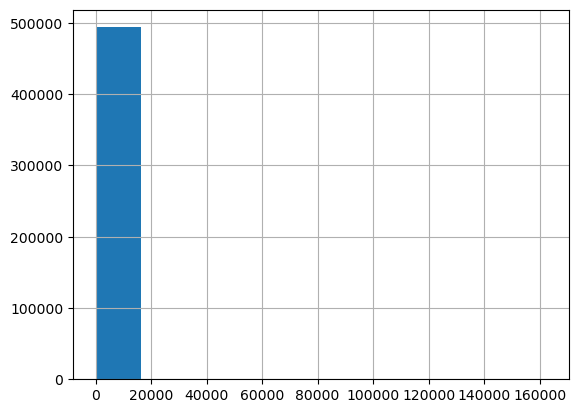

In [34]:
features["activity_score"].hist()